# Validation/Evaluation
1. Compare model performances (ROC AUC)
2. Most relevant feature (using permutation_importance)

NumPy: 2.4.6
pandas: 3.1.1
Number of rows: 319
Number of columns: 39
Dataset shape: (319, 39)
Dataset datatypes:
Gallstone Status                                    int64
Age                                                 int64
Gender                                              int64
Comorbidity                                         int64
Coronary Artery Disease (CAD)                       int64
Hypothyroidism                                      int64
Hyperlipidemia                                      int64
Diabetes Mellitus (DM)                              int64
Height                                              int64
Weight                                            float64
Body Mass Index (BMI)                             float64
Total Body Water (TBW)                            float64
Extracellular Water (ECW)                         float64
Intracellular Water (ICW)                         float64
Extracellular Fluid/Total Body Water (ECF/TBW)    float64
Total Body Fat Ra

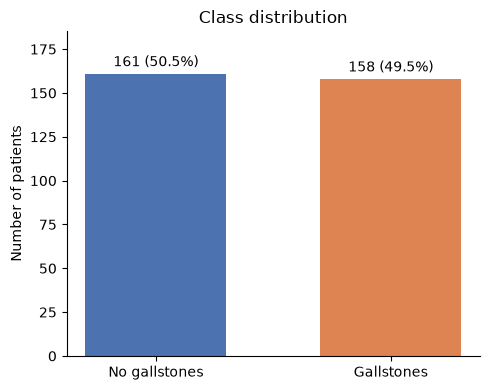

Gallstone Status  No gallstones  Gallstones
Gender                                     
Male                         94          68
Female                       67          90


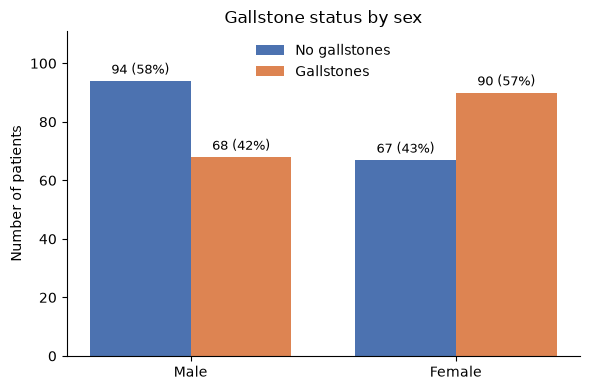

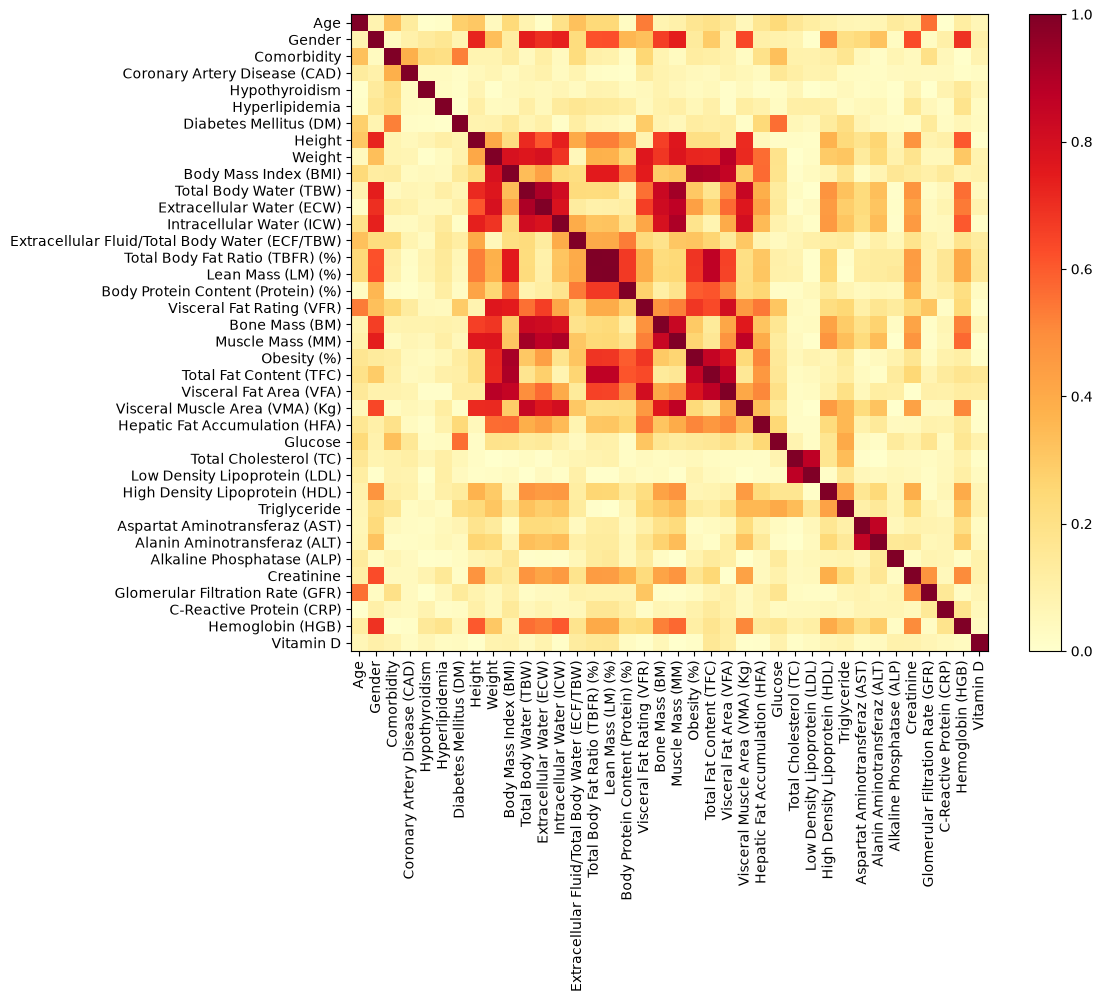

Dropped 5: ['Extracellular Water (ECW)', 'Lean Mass (LM) (%)', 'Muscle Mass (MM)', 'Obesity (%)', 'Total Fat Content (TFC)']
0      0
1      0
2      0
3      0
4      0
      ..
313    1
314    1
315    1
316    1
317    1
Name: Gallstone Status, Length: 317, dtype: int64
NumPy: 2.4.6
pandas: 3.1.1
Train: (253, 33), Test: (64, 33)

=== logreg ===
{'C': 0.001}
    accuracy: 0.664 ± 0.061  roc_auc: 0.743 ± 0.070  f1: 0.629 ± 0.084
{'C': 0.01}
    accuracy: 0.728 ± 0.064  roc_auc: 0.805 ± 0.081  f1: 0.708 ± 0.081
{'C': 0.1}
    accuracy: 0.763 ± 0.074  roc_auc: 0.845 ± 0.075  f1: 0.741 ± 0.094
{'C': 1}
    accuracy: 0.787 ± 0.044  roc_auc: 0.871 ± 0.053  f1: 0.775 ± 0.055
{'C': 10}
    accuracy: 0.807 ± 0.033  roc_auc: 0.877 ± 0.046  f1: 0.802 ± 0.034
{'C': 100}
    accuracy: 0.811 ± 0.028  roc_auc: 0.869 ± 0.049  f1: 0.806 ± 0.031
{'C': 1000}
    accuracy: 0.811 ± 0.028  roc_auc: 0.867 ± 0.050  f1: 0.806 ± 0.031
Best (by CV ROC AUC): {'C': 10} -> 0.877

=== logreg + log ===
{'C': 0.001}

,learning_rate,max_depth,n_estimators,ROC AUC mean,ROC AUC std,Accuracy mean,Accuracy std
15,0.010,4,1000,0.851,0.040,0.775,0.039
14,0.010,4,300,0.845,0.045,0.775,0.057
11,0.010,3,1000,0.844,0.049,0.767,0.051
7,0.003,4,1000,0.844,0.044,0.775,0.063
3,0.003,3,1000,0.839,0.059,0.767,0.068
10,0.010,3,300,0.839,0.059,0.767,0.068
2,0.003,3,300,0.823,0.063,0.747,0.055
9,0.010,3,100,0.822,0.066,0.751,0.057
6,0.003,4,300,0.815,0.050,0.763,0.068
13,0.010,4,100,0.814,0.049,0.763,0.063


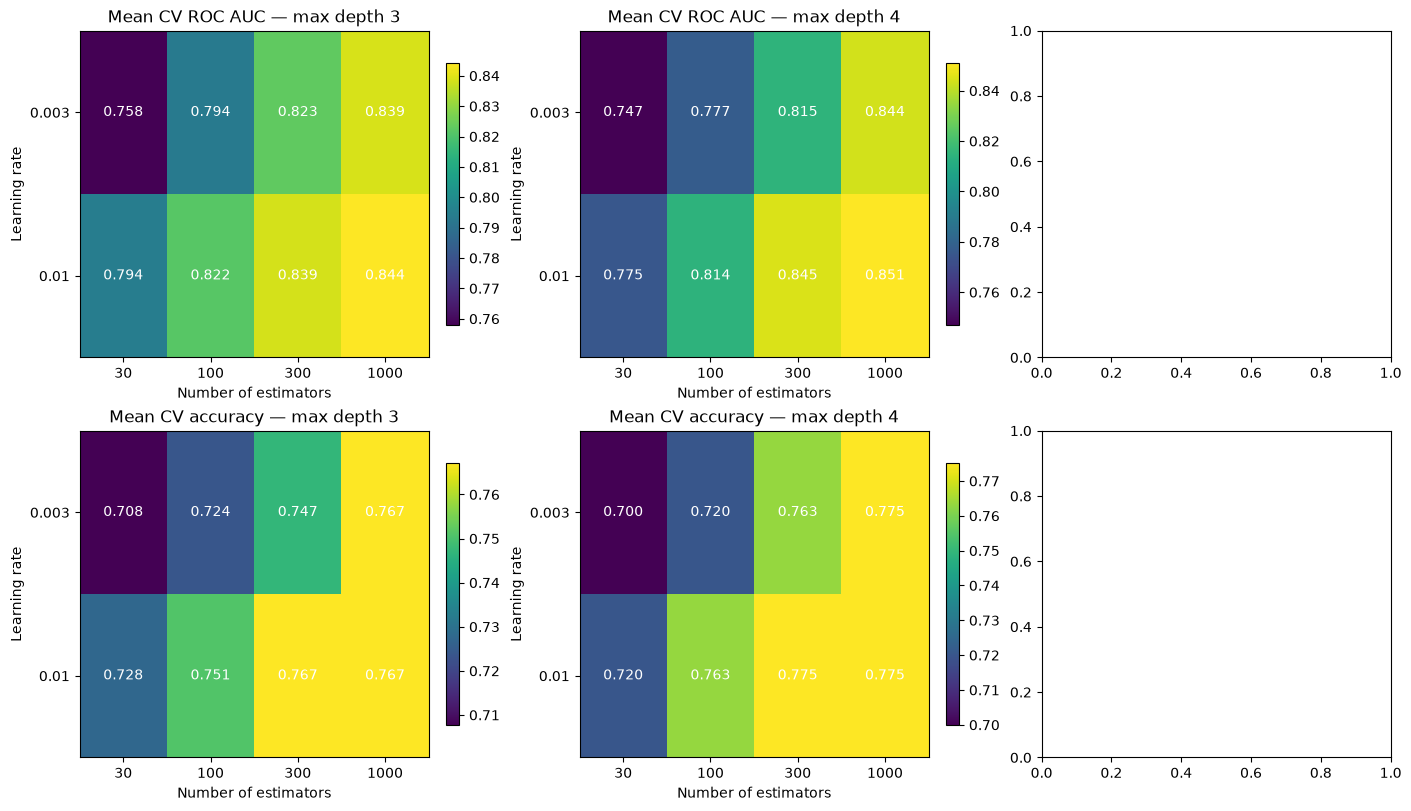

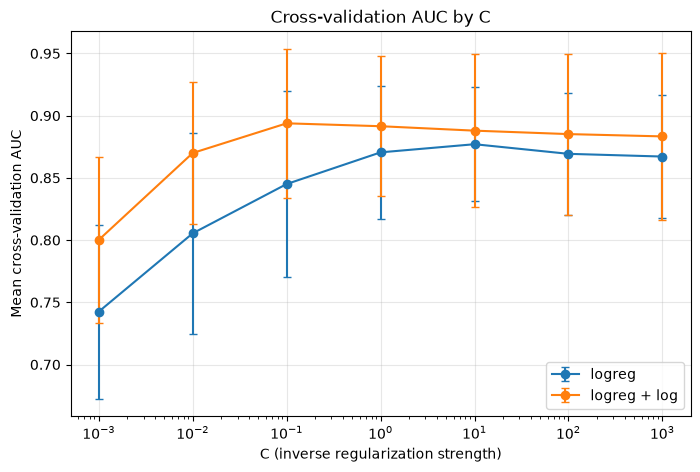

Best EBM hyperparameters (by CV ROC AUC): {'interactions': 5, 'learning_rate': 0.05, 'max_bins': 64, 'min_samples_leaf': 8}
Interaction terms used (5): ['Extracellular Fluid/Total Body Water (ECF/TBW) & Vitamin D', 'Body Protein Content (Protein) (%) & C-Reactive Protein (CRP)', 'Bone Mass (BM) & Visceral Muscle Area (VMA) (Kg)', 'Alkaline Phosphatase (ALP) & C-Reactive Protein (CRP)', 'Creatinine & C-Reactive Protein (CRP)']


In [1]:
%run ./2_model_selection.ipynb

# 1. Compare model performances (ROC AUC)
Every model is rebuilt with the best hyperparameters found in `2_` and then:
- scored with **repeated stratified 5-fold CV (5 × 5 = 25 folds)** on the training set, which gives a stable mean ± std, and
- fitted once on the full training set and evaluated **once** on the 20% test set.

In [2]:
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.inspection import permutation_importance
from sklearn.metrics import (ConfusionMatrixDisplay, RocCurveDisplay, confusion_matrix,
                             precision_score, recall_score)

rcv = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=42)

final_models = {name: make_model(name, **params) for name, params in best_params.items()}

rows, fitted, probas = [], {}, {}
for name, model in final_models.items():
    # Validation: repeated CV on the training set only
    s = cross_val_score(model, X_train, y_train, cv=rcv, scoring="roc_auc")

    # Test: fit once on the full training set, evaluate once
    m = clone(model).fit(X_train, y_train)
    fitted[name] = m
    p = m.predict_proba(X_test)[:, 1]
    pred = (p >= 0.5).astype(int)
    probas[name] = p

    rows.append({
        "Model": name,
        "CV ROC AUC": s.mean(), "CV ROC AUC std": s.std(),
        "Test ROC AUC": roc_auc_score(y_test, p),
        "Test accuracy": accuracy_score(y_test, pred),
        "Test precision": precision_score(y_test, pred),
        "Test recall": recall_score(y_test, pred),
        "Test F1": f1_score(y_test, pred),
    })

results = pd.DataFrame(rows).set_index("Model").sort_values("CV ROC AUC", ascending=False)
results.round(3)

,CV ROC AUC,CV ROC AUC std,Test ROC AUC,Test accuracy,Test precision,Test recall,Test F1
Model,,,,,,,
logreg + log,0.890,0.045,0.873,0.812,0.857,0.750,0.800
ebm,0.887,0.046,0.892,0.859,0.926,0.781,0.847
logreg,0.864,0.041,0.854,0.781,0.800,0.750,0.774
xgboost,0.837,0.048,0.877,0.828,0.920,0.719,0.807


In [3]:
# Same table formatted for the LaTeX report
latex = pd.DataFrame({
    "CV ROC AUC": [f"${r['CV ROC AUC']:.3f} \\pm {r['CV ROC AUC std']:.3f}$" for _, r in results.iterrows()],
    "Test ROC AUC": results["Test ROC AUC"].map("{:.3f}".format),
    "Test accuracy": results["Test accuracy"].map("{:.3f}".format),
}, index=results.index).reset_index()
print(latex.to_latex(index=False, column_format="lccc"))

\begin{tabular}{lccc}
\toprule
Model & CV ROC AUC & Test ROC AUC & Test accuracy \\
\midrule
logreg + log & $0.890 \pm 0.045$ & 0.873 & 0.812 \\
ebm & $0.887 \pm 0.046$ & 0.892 & 0.859 \\
logreg & $0.864 \pm 0.041$ & 0.854 & 0.781 \\
xgboost & $0.837 \pm 0.048$ & 0.877 & 0.828 \\
\bottomrule
\end{tabular}



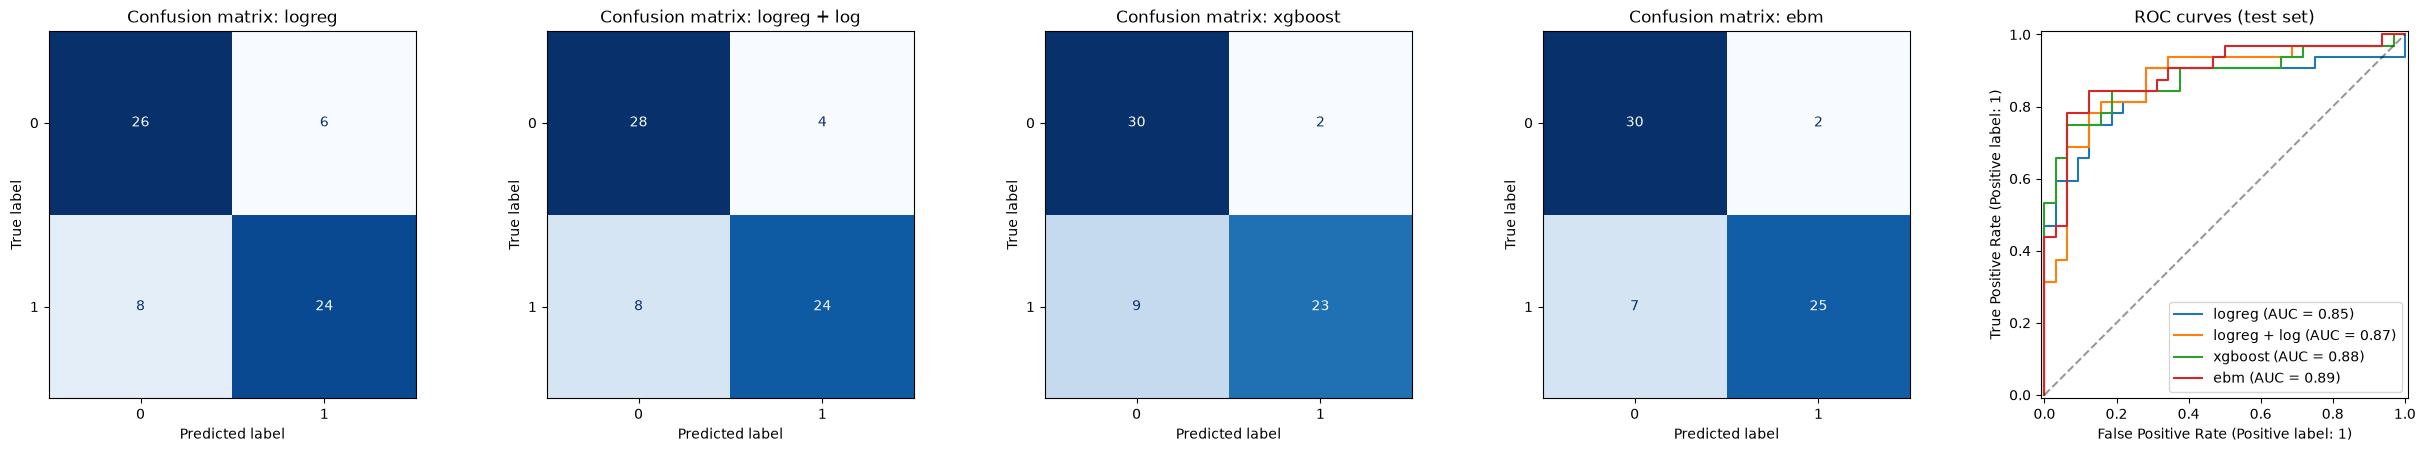

In [4]:
fig, axes = plt.subplots(1, len(fitted) + 1, figsize=(5 * (len(fitted) + 1), 4.5))

for ax, (name, m) in zip(axes, fitted.items()):
    ConfusionMatrixDisplay(confusion_matrix(y_test, (probas[name] >= 0.5).astype(int)),
                           display_labels=["0", "1"]).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(f"Confusion matrix: {name}")

for name, p in probas.items():
    RocCurveDisplay.from_predictions(y_test, p, name=name, ax=axes[-1])
axes[-1].plot([0, 1], [0, 1], "k--", alpha=0.4)
axes[-1].set_title("ROC curves (test set)")
plt.tight_layout()
plt.show()

# 2. Most relevant features (permutation importance)
For each model and each of the 25 CV folds: train on the other folds, then shuffle one feature at a time in the held-out fold and measure how much ROC AUC drops. `top5_rate` is the share of folds in which a feature ranked among the 5 most important. Features that rank high for **all** models are the most trustworthy findings.

In [5]:
summaries = {}
for name, model in final_models.items():
    fold_imp = []
    for tr, va in rcv.split(X_train, y_train):
        m = clone(model).fit(X_train.iloc[tr], y_train.iloc[tr])
        r = permutation_importance(m, X_train.iloc[va], y_train.iloc[va],
                                   scoring="roc_auc", n_repeats=10, random_state=42)
        fold_imp.append(r.importances_mean)

    imp = pd.DataFrame(fold_imp, columns=X_train.columns)
    summaries[name] = pd.DataFrame({
        "mean": imp.mean(),
        "std": imp.std(),
        "top5_rate": (imp.rank(axis=1, ascending=False) <= 5).mean(),
    }).sort_values("mean", ascending=False)
    print(f"\n{name}")
    print(summaries[name].head(10).round(3))


logreg
                                                 mean    std  top5_rate
Bone Mass (BM)                                  0.137  0.047       1.00
Total Body Fat Ratio (TBFR) (%)                 0.135  0.074       0.80
Intracellular Water (ICW)                       0.084  0.051       0.68
C-Reactive Protein (CRP)                        0.083  0.043       0.56
Gender                                          0.083  0.037       0.68
Visceral Fat Rating (VFR)                       0.059  0.030       0.40
Aspartat Aminotransferaz (AST)                  0.053  0.024       0.36
Vitamin D                                       0.050  0.019       0.12
Extracellular Fluid/Total Body Water (ECF/TBW)  0.042  0.023       0.08
Hemoglobin (HGB)                                0.034  0.019       0.04

logreg + log
                                                 mean    std  top5_rate
C-Reactive Protein (CRP)                        0.141  0.028       1.00
Vitamin D                                 

In [6]:
# How often each feature is in the top 5, per model (sorted by the total over all models)
top5 = pd.DataFrame({name: s["top5_rate"] for name, s in summaries.items()})
top5["Sum"] = top5.sum(axis=1)
top5 = top5.sort_values("Sum", ascending=False)
display(top5.head(10).round(2))
print(top5.head(10).to_latex(float_format="%.2f"))

,logreg,logreg + log,xgboost,ebm,Sum
C-Reactive Protein (CRP),0.56,1.00,1.00,1.00,3.56
Vitamin D,0.12,0.92,0.96,0.80,2.80
Bone Mass (BM),1.00,0.76,0.24,0.76,2.76
Extracellular Fluid/Total Body Water (ECF/TBW),0.08,0.72,0.80,0.88,2.48
Aspartat Aminotransferaz (AST),0.36,0.56,0.52,0.12,1.56
Intracellular Water (ICW),0.68,0.24,0.04,0.00,0.96
Total Body Fat Ratio (TBFR) (%),0.80,0.00,0.16,0.00,0.96
Visceral Muscle Area (VMA) (Kg),0.00,0.00,0.20,0.64,0.84
Hyperlipidemia,0.00,0.32,0.00,0.44,0.76
Gender,0.68,0.00,0.00,0.00,0.68


\begin{tabular}{lrrrrr}
\toprule
 & logreg & logreg + log & xgboost & ebm & Sum \\
\midrule
C-Reactive Protein (CRP) & 0.56 & 1.00 & 1.00 & 1.00 & 3.56 \\
Vitamin D & 0.12 & 0.92 & 0.96 & 0.80 & 2.80 \\
Bone Mass (BM) & 1.00 & 0.76 & 0.24 & 0.76 & 2.76 \\
Extracellular Fluid/Total Body Water (ECF/TBW) & 0.08 & 0.72 & 0.80 & 0.88 & 2.48 \\
Aspartat Aminotransferaz (AST) & 0.36 & 0.56 & 0.52 & 0.12 & 1.56 \\
Intracellular Water (ICW) & 0.68 & 0.24 & 0.04 & 0.00 & 0.96 \\
Total Body Fat Ratio (TBFR) (%) & 0.80 & 0.00 & 0.16 & 0.00 & 0.96 \\
Visceral Muscle Area (VMA) (Kg) & 0.00 & 0.00 & 0.20 & 0.64 & 0.84 \\
Hyperlipidemia & 0.00 & 0.32 & 0.00 & 0.44 & 0.76 \\
Gender & 0.68 & 0.00 & 0.00 & 0.00 & 0.68 \\
\bottomrule
\end{tabular}



# 3. EBM explanations
The EBM is a glass-box model, so besides permutation importance we can look directly inside it:
- **Term importance:** the mean absolute contribution of each feature (or interaction) to the log-odds.
- **Shape functions:** how each feature changes the risk. Above 0 raises the log-odds of gallstones, below 0 lowers it. The shaded band is the uncertainty across the EBM's bagged models.
- **Local explanation:** the exact per-feature breakdown of one patient's prediction.

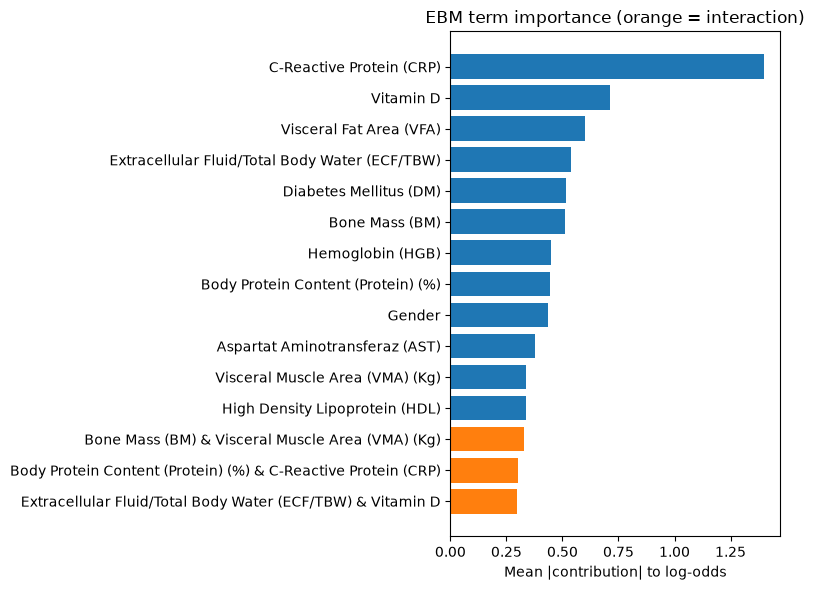

In [7]:
ebm = fitted["ebm"]
term_imp = pd.Series(ebm.term_importances(), index=ebm.term_names_).sort_values()

top = term_imp.tail(15)
plt.figure(figsize=(8, 6))
plt.barh(top.index, top.values, color=["tab:orange" if " & " in t else "tab:blue" for t in top.index])
plt.xlabel("Mean |contribution| to log-odds")
plt.title("EBM term importance (orange = interaction)")
plt.tight_layout()
plt.show()

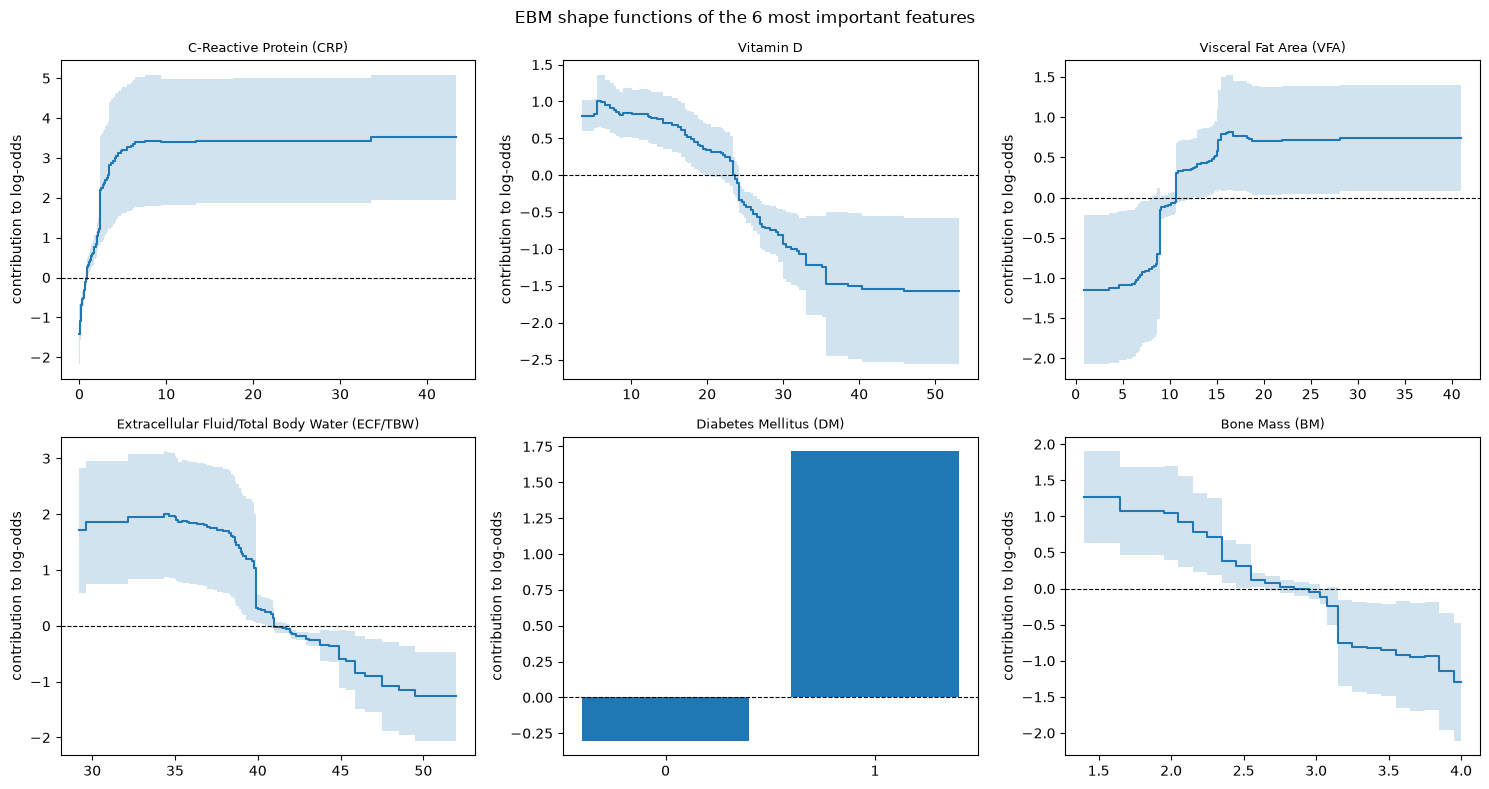

In [8]:
glob = ebm.explain_global()
term_index = {t: i for i, t in enumerate(ebm.term_names_)}

def plot_shape(term, ax):
    d = glob.data(term_index[term])
    scores, names = np.asarray(d["scores"]), d["names"]
    lo, hi = d.get("lower_bounds"), d.get("upper_bounds")
    if len(names) == len(scores) + 1:      # continuous feature: names are bin edges
        edges = np.asarray(names, dtype=float)
        ax.step(edges, np.r_[scores, scores[-1]], where="post")
        if lo is not None and hi is not None:
            ax.fill_between(edges, np.r_[lo, lo[-1]], np.r_[hi, hi[-1]], step="post", alpha=0.2)
    else:                                  # nominal feature: one bar per category
        ax.bar([str(n) for n in names], scores)
    ax.axhline(0, color="k", lw=0.8, ls="--")
    ax.set_title(term, fontsize=9)
    ax.set_ylabel("contribution to log-odds")

main_terms = [t for t in term_imp.sort_values(ascending=False).index if " & " not in t][:6]
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for t, ax in zip(main_terms, axes.ravel()):
    plot_shape(t, ax)
plt.suptitle("EBM shape functions of the 6 most important features")
plt.tight_layout()
plt.show()

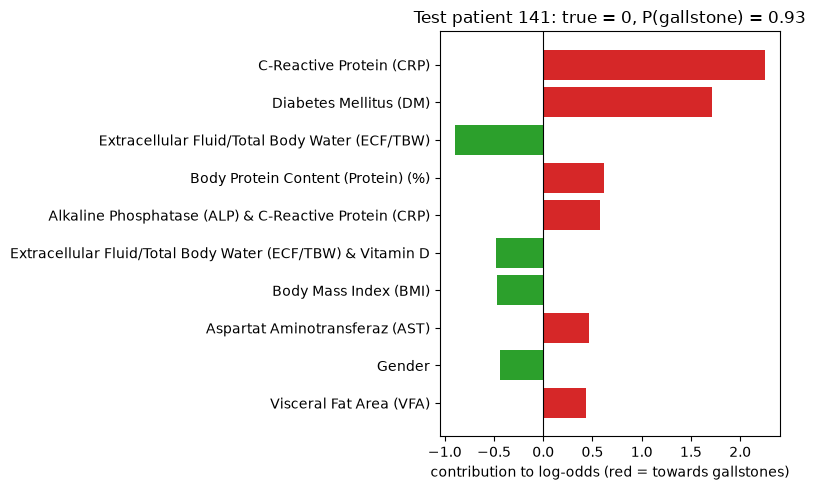

In [9]:
# Explain one misclassified test patient: which features pushed the prediction the wrong way?
p_ebm = probas["ebm"]
wrong = np.where((p_ebm >= 0.5).astype(int) != y_test.to_numpy())[0]
i = int(wrong[0]) if len(wrong) else 0

d = ebm.explain_local(X_test.iloc[[i]], y_test.iloc[[i]]).data(0)
contrib = pd.Series(d["scores"], index=d["names"])
contrib = contrib.reindex(contrib.abs().sort_values().index).tail(10)

plt.figure(figsize=(8, 5))
plt.barh(contrib.index, contrib.values, color=["tab:red" if v > 0 else "tab:green" for v in contrib.values])
plt.axvline(0, color="k", lw=0.8)
plt.xlabel("contribution to log-odds (red = towards gallstones)")
plt.title(f"Test patient {X_test.index[i]}: true = {y_test.iloc[i]}, P(gallstone) = {p_ebm[i]:.2f}")
plt.tight_layout()
plt.show()